In [ ]:
# importamos librerias basicas

# sklearn
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# basic
import pandas as pd
import spacy
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# others
from tqdm.notebook import tqdm
from collections import Counter
import plotly.graph_objects as go

from scipy.sparse import csr_matrix, hstack

# Definir random_state para reproducibilidad


In [ ]:
random_state = 42

### Diplomatura en Ciencia de Datos 2025 (Trabajo Práctico 3)
# M18: Lectura Distante de Canciones Argentinas
---

- Lautaro Puican Bertone
- Sofía Perón Santana
- Iván Kwist

---

# Trabajo Práctico 3: Clasificación automática de canciones según su estilo

En este trabajo, buscamos aplicar un pipeline completo de clasificación al conjunto de textos con el que venimos trabajando. Utilizando las técnicas de pre-procesamiento de los trabajos previos y combinando con herramientas de Procesamiento de Lenguaje Natural (NLP) buscamos asignar correctamente el estilo a las canciones partiendo de sus letras.

Utilizaremos distintas técnicas de vectorización, es decir, de representación numérica de los textos y distintos modelos de clasificación.

## Preprocesamiento de texto

Para este trabajo utilizamos el dataset previamente procesado en los trabajos anteriores. Con el objetivo de optimizar el tamaño del archivo y facilitar su disponibilidad remota, conservamos únicamente la columna de letras lematizadas, eliminando la versión original y las versiones previas.

Asimismo, se eliminaron aquellas variables que no resultan relevantes para el análisis actual, tales como: song_url, len_original, pct_reduction, track_name, lyrics_clean_final, day, month, así como las columnas numéricas 0 a 5 que denotaban las probabilidades de encontrar los tópicos dados por LDA. De el análisis del trabajo previo, se conserva únicamente en la variable tópico la de mayor probabilidad.

In [ ]:
# Leer el archivo CSV
url = "https://drive.google.com/uc?export=download&id=1hmjJNt-rSjXVMhf1ST5MuKvG23a87exM"

df = pd.read_csv(url)

Dentro de las columnas que quedan en el dataset, las siguientes fueron añadidas en los prácticos previos:

- **ttr**: relación entre palabras únicas y total de palabras (riqueza léxica).

- **lyrics_lemma**: letras después de la limpieza y lematización.

- **topico**: tópico más probable según LDA, con la opción otro si ninguna probabilidad supera el 70%.

- **topico_abs**: tópico asignado por LDA sin la categoría otro.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20736 entries, 0 to 20735
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   song_name     20736 non-null  object 
 1   artist_name   20736 non-null  object 
 2   estilo        20736 non-null  object 
 3   album         20736 non-null  object 
 4   release_date  20736 non-null  object 
 5   duration_ms   20736 non-null  float64
 6   popularity    20736 non-null  float64
 7   len_final     20736 non-null  int64  
 8   year          20736 non-null  int64  
 9   duration_s    20736 non-null  float64
 10  ttr           20602 non-null  float64
 11  lyrics_lemma  20736 non-null  object 
 12  topico        20736 non-null  object 
 13  topico_abs    20736 non-null  int64  
dtypes: float64(4), int64(3), object(7)
memory usage: 2.2+ MB


## Separación de conjuntos de entrenamiento, testeo y variable target

La variable target elegida en el trabajo práctico 1 fue *estilo*, concentraremos nuestro análisis en cómo los modelos logran clasificar las canciones de acuerdo a la misma. Para ello, la separamos de nuestro dataset.

In [ ]:
# seleccionamos la variable target y la separamos del df
target = "estilo"
y = df[target]
df = df.drop(columns=[target])

Dividimos el conjunto en entrenamiento y testeo. Notar que usaremos los mismos conjuntos para todas las técnicas para que las metodologías sean comparables.

In [ ]:
# dividimos todo el dataframe en train y test
X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.5, random_state=random_state)

# Vectorizacion


## Feature engineering

Buscamos diseñar algunas técnicas manuales de extracción de features del texto previo a la vectorización propiamente dicha.

De nuestro pre-procesamiento anterior, tenemos:

- ttr: representación de la diversidad léxica del texto, es decir, de qué tan diverso es el vocabulario que se usa.
- tópico (LDA): tópico de probabilidad alta entre los que encontramos usando LDA en el TP2 (religioso, existencial, naturista, desamor, folklorico)

Además, definimos algunas nuevas features:
- prop_stop: proporcion de stop_words
- prop_eng: proporción de palabras en inglés
- mean_leng: longitud media de palabra
- repetitions: repetición de palabras frecuentes
- polarity: sentimiento promedio de la letra, calculado como la media de los valores de polaridad de cada palabra según un lexicon de sentimiento.. En particular usamos TextBlob ( https://textblob.readthedocs.io/en/dev/api_reference.html#textblob.blob.TextBlob.polarity) que asigna valores cercanos a +1 si los textos indican contenido positivo, valores cercanos a -1 contenido negativo, y valores próximos a 0 si reflejan un tono neutro o equilibrado.

In [ ]:
from collections import Counter
from nltk.corpus import stopwords
from textblob import TextBlob
import re
from sklearn.preprocessing import StandardScaler
import nltk
nltk.download('stopwords')

stop_words = set(stopwords.words('spanish'))

# Lista de palabras en inglés (puede ampliarse)
#english_words = set(open("/usr/share/dict/words").read().lower().split())  # anda bien en Linux
# otra opción es definir un pequeño set manual
english_words = {"the","and","you","love","baby","oh","yeah"}

def extract_features(text):
    # Convertir texto a tokens si es string
    if isinstance(text, str):
        tokens = text.split()
    else:
        tokens = text

    # Filtrar solo palabras alfabéticas
    tokens = [t for t in tokens if t.isalpha()]
    n_words = len(tokens)

    if n_words == 0:
        return pd.Series([0, 0, 0, 0, 0])

    # 1. Proporción de stopwords
    prop_stop = sum(t.lower() in stop_words for t in tokens) / n_words

    # 2. Proporción de palabras en inglés
    prop_eng = sum(t.lower() in english_words for t in tokens) / n_words

    # 3. Longitud media de palabra
    mean_len = np.mean([len(t) for t in tokens])

    # 4. Repeticiones (palabra más frecuente)
    counts = Counter(tokens)
    if len(counts) > 0:
        most_common = counts.most_common(1)[0][1]
        repetitions = most_common / n_words  # normalizado
    else:
        repetitions = 0

    # 5. Sentimiento medio
    text_str = " ".join(tokens)
    polarity = TextBlob(text_str).sentiment.polarity  # entre -1 y 1

    return pd.Series([prop_stop, prop_eng, mean_len, repetitions, polarity])

# Aplicar al dataframe
X_train[['prop_stop', 'prop_eng', 'mean_word_len', 'repetitions', 'sentiment']] = X_train['lyrics_lemma'].fillna('').apply(extract_features)
X_test[['prop_stop', 'prop_eng', 'mean_word_len', 'repetitions', 'sentiment']] = X_test['lyrics_lemma'].fillna('').apply(extract_features)
df[['prop_stop', 'prop_eng', 'mean_word_len', 'repetitions', 'sentiment']] = df['lyrics_lemma'].fillna('').apply(extract_features)

feature_cols = ['prop_stop', 'prop_eng', 'mean_word_len', 'repetitions', 'sentiment', 'ttr', 'topico_abs']

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Estadísticas descriptivas de las features por estilo:

prop_stop:
            mean       min       max
estilo                              
tra     0.400368  0.000000  0.631148
rok     0.406778  0.000000  0.752137
rel     0.411770  0.093750  0.626263
can     0.422922  0.004505  0.646707
bal     0.428104  0.000000  0.646341
pop     0.434049  0.000000  0.614754
gru     0.447166  0.051948  0.610063
tro     0.450714  0.000000  0.728682

prop_eng:
            mean  min       max
estilo                         
tra     0.000613  0.0  0.200000
tro     0.001420  0.0  0.263158
can     0.001577  0.0  0.223404
gru     0.001862  0.0  0.077283
pop     0.004332  0.0  0.335196
rok     0.004746  0.0  0.547059
bal     0.005009  0.0  0.242424
rel     0.005792  0.0  0.315789

mean_word_len:
            mean       min        max
estilo                               
bal     4.199494  2.607143   6.289474
tro     4.202385  2.829457   8.000000
gru     4.210295  3.372822   5.806897
pop     4.242175  3.070312 

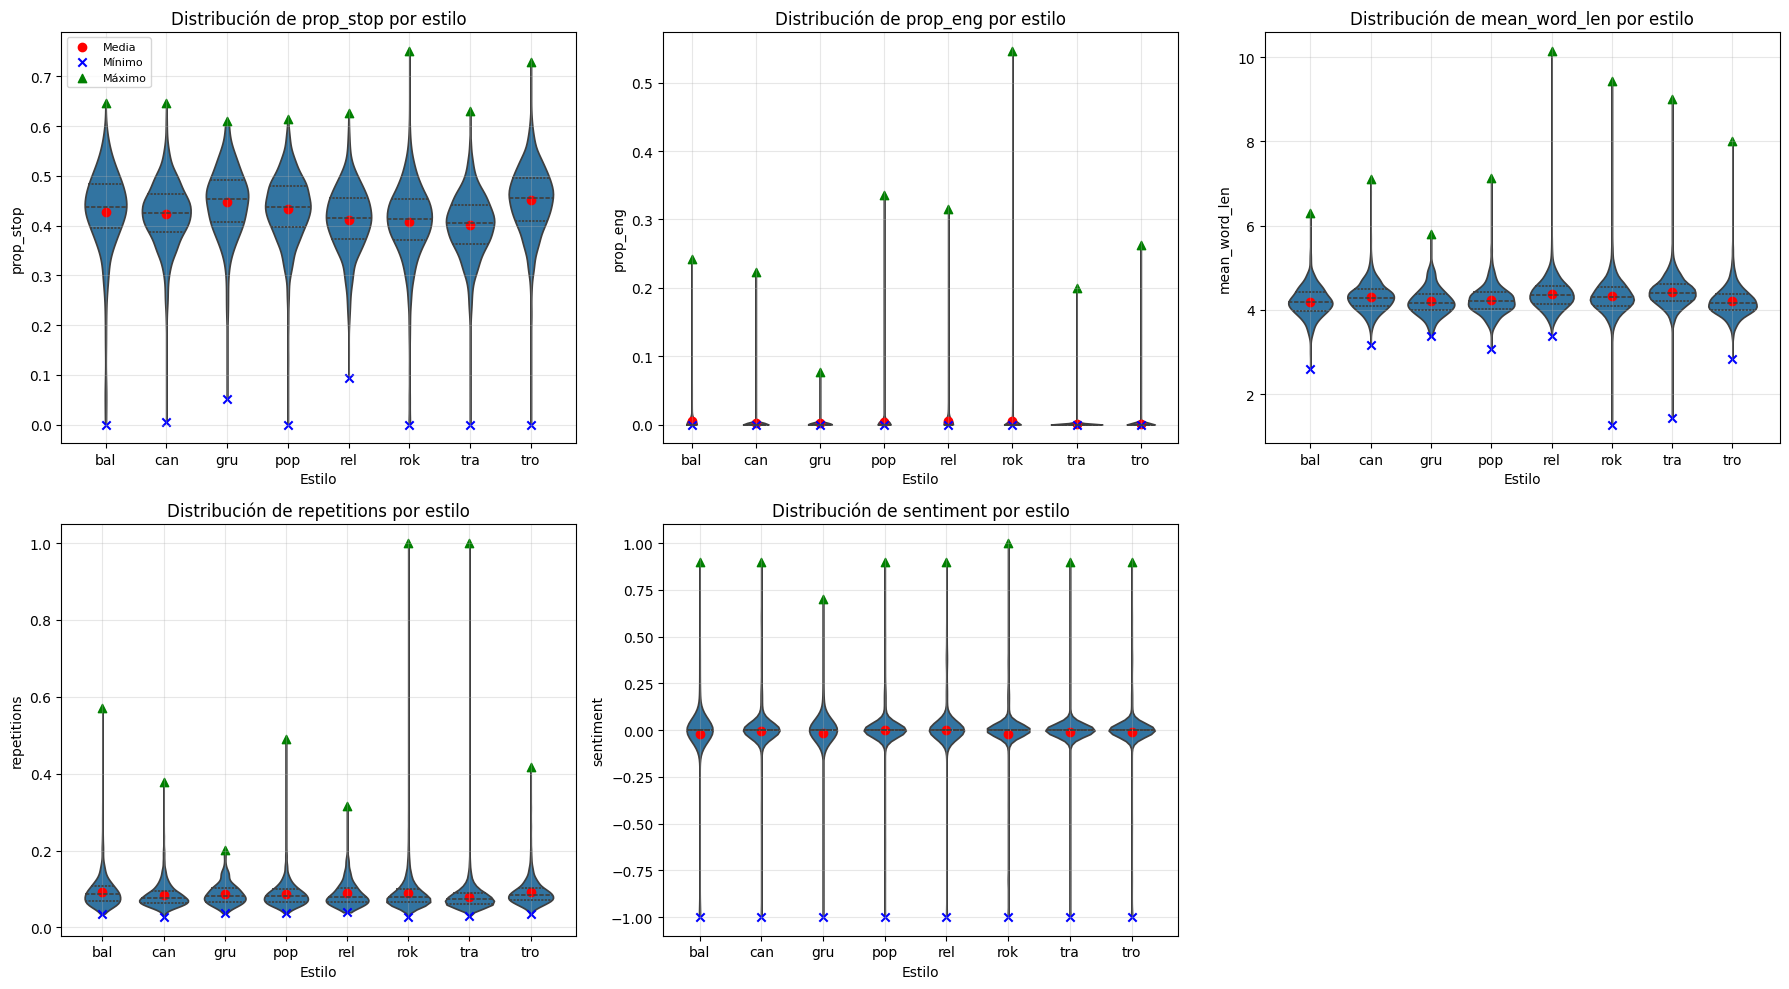

In [ ]:
# Seleccionamos las variables a graficar
features = ['prop_stop', 'prop_eng', 'mean_word_len', 'repetitions', 'sentiment']

print("Estadísticas descriptivas de las features por estilo:")
print("=" * 50)
for feature in features:
    print(f"\n{feature}:")
    stats = df.groupby(y)[feature].agg(['mean', 'min', 'max']).sort_values('mean')
    print(stats)

plt.figure(figsize=(18, 10))

for i, feature in enumerate(features, 1):
    plt.subplot(2, 3, i)
    sns.violinplot(x=y, y=df[feature], inner='quartile', cut=0)
    # Calcular medias, min y max por estilo
    stats = df.groupby(y)[feature].agg(['mean', 'min', 'max'])
    estilos = stats.index
    plt.scatter(range(len(estilos)), stats['mean'], color='red', marker='o', label='Media')
    plt.scatter(range(len(estilos)), stats['min'], color='blue', marker='x', label='Mínimo')
    plt.scatter(range(len(estilos)), stats['max'], color='green', marker='^', label='Máximo')
    plt.title(f'Distribución de {feature} por estilo')
    plt.xlabel('Estilo')
    plt.ylabel(feature)
    if i == 1:
        plt.legend(fontsize=8)
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Si bien no hay resultados fuertes si podemos corroborar algunas hipotesis:
 - El estilo tropical tiene la mayor proporción de stop_words
 - El estilo tradicional tiene palabras más largas en promedio
 - Los estilos religiosos y tradicional tienen menor proporción de palabras en inglés

Es decir, que las features elegidas tienen cierta correlación con el estilo. Más adelante, corroboraremos si es posible clasificar a partir de estas características.

In [ ]:
# Estandarizar las características para luego entrenar el modelo
# Eliminar filas con NaNs en las columnas de features antes de escalar
X_train_clean = X_train[feature_cols].dropna()
X_test_clean = X_test[feature_cols].dropna()

# Alinear los targets eliminando los índices que fueron quitados por los dropna
y_train_clean = y_train.loc[X_train_clean.index]
y_test_clean = y_test.loc[X_test_clean.index]

scaler = StandardScaler()
X_train_extracted = scaler.fit_transform(X_train_clean)
X_test_extracted = scaler.transform(X_test_clean)

## TFIDF


Vectorizamos usando TF-IDF que representa cada documento como un vector de frecuencias y, luego, ajusta estas frecuencias penalizando palabras demasiado comunes, otorgando más peso a términos discriminativos.

In [ ]:
vectorizer_params = dict(
    min_df=20,    # solo palabras en >=20 canciones
    max_df=2000,   # solo palabras en <2000 canciones
    strip_accents='ascii',
)

# vamos a vectorizar solo sobre las letras
X_train_corpus = X_train['lyrics_lemma'].fillna('')
tfidf_vectorizer = TfidfVectorizer(**vectorizer_params)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_corpus)

X_test_corpus = X_test['lyrics_lemma'].fillna('')
X_test_tfidf = tfidf_vectorizer.transform(X_test_corpus)

words_tfidf = tfidf_vectorizer.get_feature_names_out()

## Word2Vec

Word2Vec es un modelo de embeddings que representa cada palabra como un vector en un espacio continuo, de manera que palabras con significados similares quedan cerca entre sí. Permite capturar relaciones semánticas y contextuales a partir de la co-ocurrencia de palabras en un corpus.

Armamos el dataset para w2v y tokenizamos el corpus

In [ ]:
corpus_tokenized_train = [texto.split() for texto in X_train_corpus]
corpus_tokenized_test = [texto.split() for texto in X_test_corpus]

Entrenaremos el modelo de vectorización sobre nuestros datos.

In [ ]:
! pip install gensim

In [ ]:
from gensim.models import Word2Vec

# Entrenar Word2Vec sobre nuestro corpus
w2v_model = Word2Vec(sentences=corpus_tokenized_train, vector_size=100, window=5, min_count=3, workers=12, seed=random_state)

In [ ]:
w2v_model.wv["amor"]

array([-0.37746453,  1.0499356 ,  0.53490525, -1.9026312 ,  0.66655284,
       -0.58674294, -0.9288978 , -1.0932361 , -1.5082073 ,  1.131233  ,
        1.4659524 ,  1.6573297 , -0.5329506 ,  0.14001824,  0.0518403 ,
        0.4727881 , -0.02829783, -0.32184795, -0.07074133, -1.7619691 ,
       -0.92007464, -0.23108225,  0.698458  ,  0.3552289 ,  0.49617544,
       -0.21863279, -0.7228822 , -1.4997194 , -0.53988415,  0.17136437,
       -1.3556306 ,  0.23365214,  0.02737103,  0.9292702 , -2.2122684 ,
       -0.8279235 , -0.14576225, -1.1392049 ,  0.56828725, -0.47745833,
        0.22536968, -1.892675  ,  1.673848  , -0.82457954, -0.30948108,
       -0.5140478 ,  0.54869205,  2.5635052 ,  1.4091834 ,  0.2247826 ,
        0.38421318, -2.2353625 , -1.1099179 ,  0.39150605,  1.3045827 ,
       -2.0210297 ,  1.4135951 , -0.32251975,  0.98267806, -0.8803823 ,
        1.8963555 ,  0.5398194 , -1.0117745 ,  2.750272  , -0.4645208 ,
        0.3093401 , -2.1189861 , -0.89350456,  0.4925004 , -1.11

Grafiquemos las palabras utilizando pca

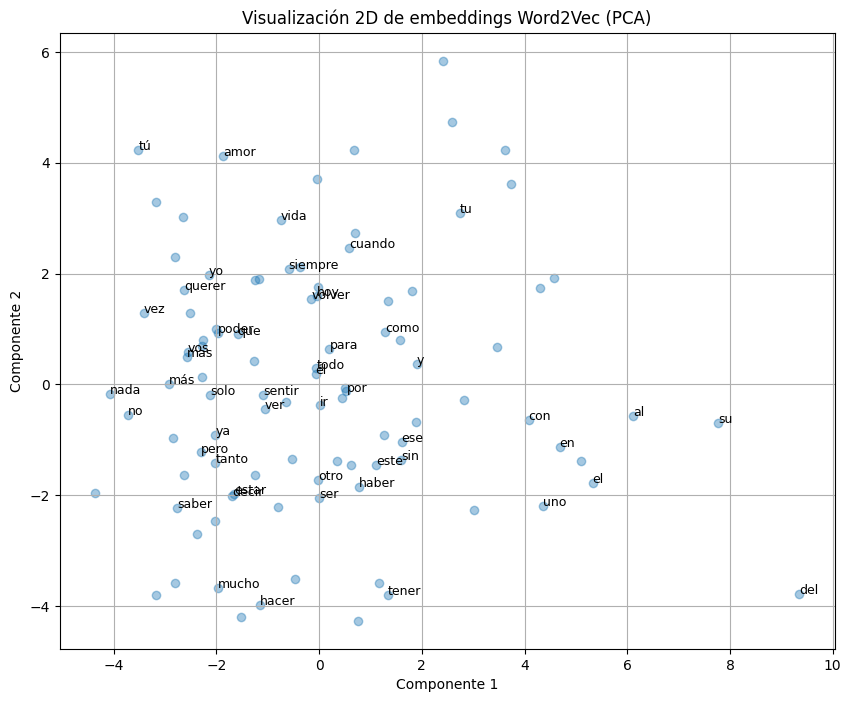

In [ ]:
from sklearn.decomposition import PCA

# primeras 100
words = list(w2v_model.wv.index_to_key)[:100]

# Vector de cada palabra:
vec_word = np.array([w2v_model.wv[w] for w in words])

# Reducir a 2D con PCA:
pca = PCA(n_components=2, random_state=random_state)
vec_2d = pca.fit_transform(vec_word)

# Graficar
plt.figure(figsize=(10,8))
plt.scatter(vec_2d[:,0], vec_2d[:,1], alpha=0.4)

for i, word in enumerate(words[:50]):
    plt.annotate(word, (vec_2d[i,0], vec_2d[i,1]), fontsize=9)

plt.title("Visualización 2D de embeddings Word2Vec (PCA)")
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.grid(True)
plt.show()

#### Transfer learning


Utilizamos el modelo preentrenado que fue provisto por la catedra, asignaremos los pesos y cargamos el df para ser utilizado en la clasificación

In [ ]:
! pip install huggingface_hub

In [ ]:
from huggingface_hub import hf_hub_download

repo_id = "fcalabro/wiki_es_m18"
filename = "w2v_wiki_es_m18.kv"

model_path = hf_hub_download(repo_id=repo_id, filename=filename, local_dir=".")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


w2v_wiki_es_m18.kv:   0%|          | 0.00/31.8M [00:00<?, ?B/s]

In [ ]:
from gensim.models.keyedvectors import KeyedVectors

word_vectors_sp = KeyedVectors.load("w2v_wiki_es_m18.kv")

Convertimos los vectores de cada palabra en el vector de canción

In [ ]:
# Vectorizá cada canción en funcion de  los pesos de tfidf que generamos en la vectorizacion
idf_dict = dict(zip(words_tfidf, tfidf_vectorizer.idf_))
def sent_vec_weighted_sp(wordlist):
    vecs = []
    for w in wordlist:
        w_low = w.lower()
        if w_low in word_vectors_sp.key_to_index:
            weight = idf_dict.get(w_low, 1.0)
            vecs.append(word_vectors_sp[w_low] * weight)
    if not vecs:
        return np.zeros(word_vectors_sp.vector_size)
    return np.mean(vecs, axis=0).reshape(1, -1)

X_train_w2v = np.vstack([sent_vec_weighted_sp(doc) for doc in corpus_tokenized_train])
X_test_w2v = np.vstack([sent_vec_weighted_sp(doc) for doc in corpus_tokenized_test])

# Repetimos esto para el modelo que entramos nosotres
def sent_vec_weighted_own_model(wordlist):
    """
    Convert a list of words to a sentence vector using your own trained model
    """
    vecs = []
    for w in wordlist:
        w_low = w.lower()
        if w_low in w2v_model.wv.key_to_index:
            # Use TF-IDF weight if available, otherwise use 1.0
            weight = idf_dict.get(w_low, 1.0)
            vecs.append(w2v_model.wv[w_low] * weight)

    if not vecs:
        return np.zeros(w2v_model.wv.vector_size)
    return np.mean(vecs, axis=0).reshape(1, -1)

X_train_w2v_own = np.vstack([sent_vec_weighted_own_model(doc) for doc in corpus_tokenized_train])
X_test_w2v_own = np.vstack([sent_vec_weighted_own_model(doc) for doc in corpus_tokenized_test])

## BERT

**Embedding pre entrenados**

Utilizaremos el modelo pre-entreado en español https://huggingface.co/dccuchile/bert-base-spanish-wwm-cased .

In [ ]:
from transformers import AutoTokenizer, AutoModel
import torch

# Para uncased (no sensible a mayúsculas)
tokenizer = AutoTokenizer.from_pretrained('dccuchile/bert-base-spanish-wwm-cased')
model = AutoModel.from_pretrained('dccuchile/bert-base-spanish-wwm-cased')


def get_bert_embeddings(texts, model, tokenizer, max_len=128):
    model.eval()
    embeddings = []
    with torch.no_grad(): # Disable gradient calculation for inference
        for text in tqdm(texts, desc="Generating BERT Embeddings"):
            # Tokenize and encode the text
            encoded_input = tokenizer(text, return_tensors='pt', padding='max_length', truncation=True, max_length=max_len)
            input_ids = encoded_input['input_ids']
            attention_mask = encoded_input['attention_mask']

            # Get model output
            output = model(input_ids=input_ids, attention_mask=attention_mask)

            # Get the embeddings for the [CLS] token (usually used as a sentence representation)
            # You could also average the embeddings of all tokens or use other pooling strategies
            cls_embedding = output.last_hidden_state[:, 0, :].squeeze().numpy()
            embeddings.append(cls_embedding)
    return np.array(embeddings)


tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertModel were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-cased and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
X_train_bert = get_bert_embeddings(X_train['lyrics_lemma'].tolist(), model, tokenizer)
X_test_bert = get_bert_embeddings(X_test['lyrics_lemma'].tolist(), model, tokenizer)

Generating BERT Embeddings:   0%|          | 0/10368 [00:00<?, ?it/s]

# Clasificación

Veremos los resultados de los clasificadores para las distintas vectorizaciones, almacenamos esa información en un DataFrame.

In [ ]:
from sklearn.metrics import f1_score, classification_report

resultados = pd.DataFrame(columns=["Clasificador", "Vectorización", "Accuracy", "Macro F1", "Micro F1", "Weighted F1"])

## Feature Engineering



### 1a) FE + Regresión Logística

In [ ]:
clf_FE_RL = LogisticRegression(multi_class='multinomial', max_iter=500, class_weight='balanced', random_state=random_state)
clf_FE_RL.fit(X_train_extracted, y_train_clean)
y_pred_FE_RL = clf_FE_RL.predict(X_test_extracted)

print(classification_report(y_test_clean, y_pred_FE_RL))

resultados.loc[len(resultados)] = {
    "Clasificador": "Regresión Logística",
    "Vectorización": "Feature Extraction",
    "Accuracy": np.round(clf_FE_RL.score(X_test_extracted, y_test_clean),4),
    "Macro F1": np.round(f1_score(y_test_clean, y_pred_FE_RL, average='macro'),4),
    "Micro F1": np.round(f1_score(y_test_clean, y_pred_FE_RL, average='micro'),4),
    "Weighted F1": np.round(f1_score(y_test_clean, y_pred_FE_RL, average='weighted'),4)
}

### 1b) FE + SVC

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report

clf_FE_SVC = LinearSVC(max_iter=2000, random_state=random_state, class_weight='balanced')
clf_FE_SVC.fit(X_train_extracted, y_train_clean)
y_pred_FE_SVC = clf_FE_SVC.predict(X_test_extracted)

print("SVM Classification Report:")
print(classification_report(y_test_clean, y_pred_FE_SVC))

resultados.loc[len(resultados)] = {
    "Clasificador": "SVM",
    "Vectorización": "Feature Extraction",
    "Accuracy": np.round(clf_FE_SVC.score(X_test_extracted, y_test_clean), 4),
    "Macro F1": np.round(f1_score(y_test_clean, y_pred_FE_SVC, average='macro'), 4),
    "Micro F1": np.round(f1_score(y_test_clean, y_pred_FE_SVC, average='micro'), 4),
    "Weighted F1": np.round(f1_score(y_test_clean, y_pred_FE_SVC, average='weighted'), 4)
}

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_clean, y_pred_FE_SVC, labels=clf_FE_SVC.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf_FE_SVC.classes_)
fig, ax = plt.subplots(figsize=(10,8))
disp.plot(ax=ax, cmap='Blues')
plt.title('Matriz de Confusión')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()

## TF-IDF

### 2a) Regresion Logística (Baseline)

In [ ]:
clf_TF_RL = LogisticRegression(multi_class='multinomial', max_iter=500, class_weight='balanced', random_state=random_state)
clf_TF_RL.fit(X_train_tfidf, y_train)
y_pred_TF_RL = clf_TF_RL.predict(X_test_tfidf)

resultados.loc[len(resultados)] = {
    "Clasificador": "Regresión Logística",
    "Vectorización": "TF-IDF",
    "Accuracy": np.round(clf_TF_RL.score(X_test_tfidf, y_test), 4),
    "Macro F1": np.round(f1_score(y_test, y_pred_TF_RL, average='macro'), 4),
    "Micro F1": np.round(f1_score(y_test, y_pred_TF_RL, average='micro'), 4),
    "Weighted F1": np.round(f1_score(y_test, y_pred_TF_RL, average='weighted'), 4)
}

print(classification_report(y_test, y_pred_TF_RL))

In [ ]:
report = classification_report(y_test, y_pred_TF_RL, output_dict=True)
df_report = pd.DataFrame(report).transpose()
df_report = df_report.iloc[:-3]  # saca avg/accuracy/support

df_report[['precision', 'recall', 'f1-score']].plot(kind='bar', figsize=(12,6))
plt.title('Métricas por clase')
plt.ylabel('Score')
plt.xlabel('Género (estilo musical)')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Para este que es el caso base, hacemos un análisis de los coeficientes. Se observa la distribución de palabras usadas para predecir cada estilo.

In [ ]:
top_n = 10
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=False)
estilos = clf_TF_RL.classes_

for idx, estilo in enumerate(estilos):
    i_clase = list(clf_TF_RL.classes_).index(estilo)
    coefs = clf_TF_RL.coef_[i_clase][:len(tfidf_vectorizer.get_feature_names_out())]
    top_idx = np.argsort(coefs)[-top_n:]
    ax = axes.flat[idx]
    ax.barh(np.array(tfidf_vectorizer.get_feature_names_out())[top_idx], coefs[top_idx])
    ax.set_title(f"Palabras más importantes para '{estilo}'")
    ax.set_xlabel('Coeficiente')
    ax.set_ylabel('Palabra')

plt.tight_layout()
plt.show()

Además observamos la matriz de confusión

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_TF_RL, labels=clf_TF_RL.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf_TF_RL.classes_)
fig, ax = plt.subplots(figsize=(10,8))
disp.plot(ax=ax, cmap='Blues')
plt.title('Matriz de Confusión')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()

#### Analisis de Coeficientes

El hecho de trabajar con Logistic Rgression nos permite obtener el peso o la importancia que le da el modelo a cada uno de los features (palabras en este caso) para cada uno de los generos.

La magnitud de estos coeficientes nos dice el impacto que tienen estas palabras en cada estilo y el signo nos dirá si esta asociación es positiva o negaiva.

In [ ]:
feature_names = tfidf_vectorizer.get_feature_names_out()
coefficients = clf_TF_RL.coef_

df_coef = pd.DataFrame(
    data=coefficients.T,
    index=feature_names,
    columns=clf_TF_RL.classes_
)

df_coef.sort_values(by="tro", ascending=1).head(10)

Tras analizar estos coeficientes, encontramos las siguientes palabras destacadas para cada estilo:

| Estilo | Positivas (+) | Negativas (-) |
| :--- | :---: | ---: |
| bal | rosa querido pensar | muerte sombra mirar |
| can | escribir pueblo descansar | feliz contigo mia |
| gru | baby locura adivinar | sangre luz cancion |
| pop | querer ideal bar | sufrir marchar luna |
| rel | jesus espíritu dios | ciudad pensar pena |
| rok | punk mierda aguante | beso llorar santo |
| tra | cantor andar monte | mundo intentar antes |
| tro | cumbia cuerpo cariño | luz rio profundo |

A partir de esto llegamos a las siguientes conclusiones:

* **Balada**: Imagenes relacionadas al amor. Relación negativa con temas oscuros.
* **Cantautor**: Temas más profundos e idealistas.
* **Grupero**: Temas románticos o livianos. Relacion negativa con temas complejos.
* **Pop**: Temas romanticos y cotidianos. Relacion negativa con temas profundos.
* **Religioso**: Temas espirituales y religiosos. Relacion negativa con temas cotidianos.
* **Rock**: Temas mundanos y agresivos. Relación negativa con palabras romanticas y religiosas.
* **Tradicional**: Temas tradicionales y autóctonos.
* **Tropical**: Autorreferencial, relaciones interpersonales y románticas. Relación negativa con tematicas profundas o espirituales.

Continuamos con el siguiente caso
### 2b) Tf-IDF + SVC

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report

clf_TF_SVC = LinearSVC(max_iter=2000, random_state=random_state)
clf_TF_SVC.fit(X_train_tfidf, y_train)
y_pred_TF_SVC = clf_TF_SVC.predict(X_test_tfidf)

print("SVM Classification Report:")
print(classification_report(y_test, y_pred_TF_SVC))

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_TF_SVC, labels=clf_TF_SVC.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf_TF_SVC.classes_)
fig, ax = plt.subplots(figsize=(10,8))
disp.plot(ax=ax, cmap='Blues')
plt.title('Matriz de confusión SVM')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()

## Sobre W2V

Vemos la diferencia entre usar el modelo preentrenado y un modelo entrenado sobre nuestros propios datos.

### 3a) Regresion Lineal

#### Usando el modelo entrenado con nuestros datos

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Entrená regresión logística multinomial (para clasificación multiclase)
clf_W2V_RL_OWN = LogisticRegression(max_iter=1000, multi_class='multinomial', random_state=random_state, class_weight='balanced')
clf_W2V_RL_OWN.fit(X_train_w2v_own, y_train)

# Predicciones
y_pred_W2V_RL_OWN = clf_W2V_RL_OWN.predict(X_test_w2v_own)

# Evaluación
print(classification_report(y_test, y_pred_W2V_RL_OWN, zero_division=0))

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(y_test, y_pred_W2V_RL_OWN, zero_division=0, output_dict=True)
df_report = pd.DataFrame(report).transpose().iloc[:-3]  # Solo clases, saca los promedios globales

df_report[['precision','recall','f1-score']].plot(
    kind='bar', figsize=(12,6), color=['cornflowerblue','salmon','mediumseagreen']
)

plt.title('Performance por estilo musical (Word2Vec + Regresión Logística)')
plt.ylabel('Score')
plt.xlabel('Estilo musical')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [ ]:
cm = confusion_matrix(y_test, y_pred_W2V_RL_OWN, labels=clf_W2V_RL_OWN.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf_W2V_RL_OWN.classes_)
fig, ax = plt.subplots(figsize=(10,8))
disp.plot(ax=ax, cmap='Blues')
plt.title('Matriz de Confusión')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()

#### Usando el modelo pre - entrenado

In [ ]:
# Entrená regresión logística multinomial (para clasificación multiclase)
clf_W2V_RL = LogisticRegression(max_iter=1000, multi_class='multinomial', random_state=random_state, class_weight='balanced')
clf_W2V_RL.fit(X_train_w2v, y_train)

# Predicciones
y_pred_W2V_RL = clf_W2V_RL.predict(X_test_w2v)

# Evaluación
print(classification_report(y_test, y_pred_W2V_RL, zero_division=0))

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(y_test, y_pred_W2V_RL, zero_division=0, output_dict=True)
df_report = pd.DataFrame(report).transpose().iloc[:-3]  # Solo clases, saca los promedios globales

df_report[['precision','recall','f1-score']].plot(
    kind='bar', figsize=(12,6), color=['cornflowerblue','salmon','mediumseagreen']
)

plt.title('Performance por estilo musical (Word2Vec + Regresión Logística)')
plt.ylabel('Score')
plt.xlabel('Estilo musical')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [ ]:
cm = confusion_matrix(y_test, y_pred_W2V_RL, labels=clf_W2V_RL_OWN.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf_W2V_RL_OWN.classes_)
fig, ax = plt.subplots(figsize=(10,8))
disp.plot(ax=ax, cmap='Blues')
plt.title('Matriz de Confusión')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()

### 3b) svm

#### usando el modelo entrenado con nuestros datos

In [ ]:
# Entrenamiento de una SVM lineal multiclase
clf_W2V_SVC_OWN = LinearSVC(max_iter=2000, random_state=random_state, class_weight='balanced')
clf_W2V_SVC_OWN.fit(X_train_w2v_own, y_train)

# Predicción
y_pred_W2V_SVC_OWN = clf_W2V_SVC_OWN.predict(X_test_w2v_own)

# Evaluación
print(classification_report(y_test, y_pred_W2V_SVC_OWN, zero_division=0))

In [ ]:
cm = confusion_matrix(y_test, y_pred_W2V_SVC_OWN, labels=clf_W2V_SVC_OWN.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf_W2V_SVC_OWN.classes_)
fig, ax = plt.subplots(figsize=(10,8))
disp.plot(ax=ax, cmap='Blues')
plt.title('Matriz de confusión SVM')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()

#### usando el modelo pre-entrenado

In [ ]:
# Entrenamiento de una SVM lineal multiclase
clf_W2V_SVC = LinearSVC(max_iter=2000, random_state=random_state, class_weight='balanced')
clf_W2V_SVC.fit(X_train_w2v, y_train)

# Predicción
y_pred_W2V_SVC = clf_W2V_SVC.predict(X_test_w2v)

# Evaluación
print(classification_report(y_test, y_pred_W2V_SVC, zero_division=0))

In [ ]:
cm = confusion_matrix(y_test, y_pred_W2V_SVC, labels=clf_W2V_SVC.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf_W2V_SVC.classes_)
fig, ax = plt.subplots(figsize=(10,8))
disp.plot(ax=ax, cmap='Blues')
plt.title('Matriz de confusión SVM')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()

## BERT

### BERT + Regresion Lineal

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Entrená regresión logística multinomial (para clasificación multiclase)
clf_BERT_RL = LogisticRegression(max_iter=1000, multi_class='multinomial', random_state=random_state)
clf_BERT_RL.fit(X_train_bert, y_train)

# Predicciones
y_pred_BERT_RL = clf_BERT_RL.predict(X_test_bert)

# Evaluación
print(classification_report(y_test, y_pred_BERT_RL, zero_division=0))

# Add the results to the results dataframe
resultados.loc[len(resultados)] = {
    "Clasificador": "Regresión Logística",
    "Vectorización": "BERT Embeddings",
    "Accuracy": np.round(clf_BERT_RL.score(X_test_bert, y_test), 4),
    "Macro F1": np.round(f1_score(y_test, y_pred_BERT_RL, average='macro'), 4),
    "Micro F1": np.round(f1_score(y_test, y_pred_BERT_RL, average='micro'), 4),
    "Weighted F1": np.round(f1_score(y_test, y_pred_BERT_RL, average='weighted'), 4)
}

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt

report = classification_report(y_test, y_pred_BERT_RL, zero_division=0, output_dict=True)
df_report = pd.DataFrame(report).transpose().iloc[:-3]  # Solo clases, saca los promedios globales

df_report[['precision','recall','f1-score']].plot(
    kind='bar', figsize=(12,6), color=['cornflowerblue','salmon','mediumseagreen']
)

plt.title('Performance por estilo musical (BERT Embeddings + Regresión Logística)')
plt.ylabel('Score')
plt.xlabel('Estilo musical')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_BERT_RL, labels=clf_BERT_RL.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf_BERT_RL.classes_)
fig, ax = plt.subplots(figsize=(10,8))
disp.plot(ax=ax, cmap='Blues')
plt.title('Matriz de Confusión (BERT Embeddings + Regresión Logística)')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()

### BERT + SVM

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, f1_score

# Entrenamiento de una SVM lineal multiclase
clf_BERT_SVC = LinearSVC(max_iter=2000, random_state=random_state)
clf_BERT_SVC.fit(X_train_bert, y_train)

# Predicción
y_pred_BERT_SVC = clf_BERT_SVC.predict(X_test_bert)

# Evaluación
print(classification_report(y_test, y_pred_BERT_SVC, zero_division=0))

# Add the results to the results dataframe
resultados.loc[len(resultados)] = {
    "Clasificador": "SVM",
    "Vectorización": "BERT Embeddings",
    "Accuracy": np.round(clf_BERT_SVC.score(X_test_bert, y_test), 4),
    "Macro F1": np.round(f1_score(y_test, y_pred_BERT_SVC, average='macro'), 4),
    "Micro F1": np.round(f1_score(y_test, y_pred_BERT_SVC, average='micro'), 4),
    "Weighted F1": np.round(f1_score(y_test, y_pred_BERT_SVC, average='weighted'), 4)
}

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt

report = classification_report(y_test, y_pred_BERT_SVC, zero_division=0, output_dict=True)
df_report = pd.DataFrame(report).transpose().iloc[:-3]  # Solo clases, saca los promedios globales

df_report[['precision','recall','f1-score']].plot(
    kind='bar', figsize=(12,6), color=['cornflowerblue','salmon','mediumseagreen']
)

plt.title('Performance por estilo musical (BERT Embeddings + LinearSVC)')
plt.ylabel('Score')
plt.xlabel('Estilo musical')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_BERT_SVC, labels=clf_BERT_SVC.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf_BERT_SVC.classes_)
fig, ax = plt.subplots(figsize=(10,8))
disp.plot(ax=ax, cmap='Blues')
plt.title('Matriz de Confusión (BERT Embeddings + LinearSVC)')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()

# Analisis de Resultados

Ahora que hemos probado nuestras tecnicas en distintos modelos, veamos el desempeño de cada uno de ellos. La métrica que eligieremos para determinar el mejor modelo es la de macro average f1-score. De esta manera, podemos tener en consideración la naturaleza desbalanceada de nuestro set de datos y hacer una comparación justa.

| Tecnica | Modelo | Score |
| :--- | :---: | ---: |
| Feature Engineering | Logistic Regression | 0.14 |
| Feature Engineering | Support Vector Machines | 0.18 |
| TF-IDF | Logistic Regression | 0.37 |
| TF-IDF | Support Vector Machines | 0.34 |
| Word2Vec (propio)| Logistic Regression | 0.32 |
| Word2Vec (propio)| Support Vector Machines | 0.33 |
| Word2Vec (pre-entrenado)| Logistic Regression | 0.26 |
| Word2Vec (pre-entrenado)| Support Vector Machines | 0.27 |
| BERT| Logistic Regression | 0.33 |
| BERT| Support Vector Machines | 0.35 |

Podemos ver entonces que la mejor combinación fue la de TF-IDF y Logistic Regression que es el modelo baseline. Es posible que las fallas en clasificación tengan más que ver con el desbalance en la representación de las clases que con el modelo utilizado. Incluso usando transformers que es una técnica más sofisticada y que de hecho tarda mucho más en hacer la vectorización, los resultados no mejoran.

## Analisis de Errores

Tenemos la oportunidad de ver las canciones que nuestro mejor modelo no pudo clasificar correctamente. A modo de ejercicio, analizaremos manualmente estos casos y veremos si tiene sentido la elección de nuestro modelo.

### Ejemplo 1

Un ejemplo curioso que encontramos fue el de la canción "Que me falte todo" de Luck Ra:

```
Y este tema va dedicado para todos
Los que alguna vez
Sufrimos de corazón roto
Y dice algo como
Hey
Lo que daría
Por volver a cuando es que tú me querías
Llego a casa y cada vez está más fría
Y mi cama hoy se siente tan vacía
No mentía cuando te decía
Tú y yo, no quiero nada a menos que seas
Tú y yo, no quiero que termine lo de
Tú y yo, no quiero nada a menos que seas tú
Y que me falte todo y no tenga nada
Y estemos juntos otra madrugada
Y me falte todo y no tenga nada
Y estemos solos otra madrugada
Y tenemos al invitado especial
Un fuerte aplauso para Abel Pintos
Y estar contigo se siente como un hogar
Las noches son más frías cuando tú no estás
Me duele pensar que otro ocupe mi lugar
Y aunque quieras dudar
No mentía cuando te decía
Tú y yo, no quiero nada a menos que seas
Tú y yo, no quiero que termine lo de
Tú y yo, no quiero nada a menos que seas tú
Y que me falte todo y no tenga nada
Y estemos juntos otra madrugada
Y me falte todo y no tenga nada
Y estemos solos otra madrugada
Y que me falte todo y no tenga nada
Y estemos juntos otra madrugada
Y me falte todo y no tenga nada
Y estemos solos otra madrugada
```

In [ ]:
song_id = 1777

print("Estilo Real: {}".format(y_test.iloc[song_id]))
print("Estilo Predicho: {}".format(y_pred_TF_RL[song_id]))

X_test.iloc[song_id]

Podemos ver que el estilo etiquetado en LaCuerda es "cantautor", mientras que el de nuestro modelo es "tropical". Teniendo en cuenta el genero usual de este artista, habiendo escuchado la cancion y habiendo leido la letra, creemos que la etiqueta de "tropical" es más apropiada para esta canción.

### Ejemplo 2

Otro caso que nos pareció muy interesante fue el de la canción "Crece" de la banda Corto Plazo:

```
Solo un rato pasó
Unos pocos segundos marcó mi reloj
Y se produce en mí una desesperación
Otra vez deseo estar con vos
Quiero volverte a ver
Tal vez esto a vos te pueda sorprender
Es que con el tiempo logré entender
Que de nadie más yo puedo depender
Crece, el amor que siento por vos crece
No puedo evitarlo aunque a veces
Piense que es exagerado amarte así
Me enorgullece y al mismo tiempo me enloquece
Ver como esta relación hoy crece
Y no hay nada que me haga más feliz
Todo lo que yo soy
Mi cuerpo, mi alma, mente y corazón
A vos te pertenecen porque tuyo soy
Porque muero si no estoy con vos
La verdad, el camino y la vida que pude encontrar
Incomparable amor que me puede salvar
Y amarme en forma incondicional
Crece, el amor que siento por vos crece
No puedo evitarlo aunque a veces
Piense que es exagerado amarte así
Me enorgullece y al mismo tiempo me enloquece
Ver como esta relación hoy crece
Y no hay nada que me haga más feliz
Solo un rato pasó
Y otra vez deseo estar con vos
```

In [ ]:
song_id = 382

print("Estilo Real: {}".format(y_test.iloc[song_id]))
print("Estilo Predicho: {}".format(y_pred_TF_RL[song_id]))

X_test.iloc[song_id]

Como podemos observar, el estilo de la cancion según LaCuerda es "religioso" y según nuestro modelo se trata de una canción de "rock". Creemos que esto se debe a que, si bien conociendo el género y las tematicas de la banda es claro que la canción está hablandole a Dios, nunca lo menciona directamente y en lugar de ello le habla al oyente. Esto es algo que suelen hacer las canciones con un interés romántico, lo que puede causar la confusión de nuestro modelo. Sabiendo que por un tema de balance del dataset nuestros modelos tendrán un sesgo a clasificar las cosas como rock, esta cancion podría caer en esa categoría.

Aunque quede por fuera de este analisis, curiosamente la instrumentación de la canción se acerca más a un rock o pop-punk. Este es un punto interesante sobre el cual detenerse. ¿Qué determina el "estilo" de una canción?

## Clustering con k-means

### Clustering + tfidf

In [ ]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
df_tfidf = df.copy()

# Primero aplicamos PCA para reducir dimensionalidad
print("Aplicando PCA para reducir dimensionalidad...")
pca = PCA(n_components=12, random_state=random_state)  # Mantenemos 12 componentes principales
X_pca = pca.fit_transform(X_train_tfidf)

# Mostrar información sobre la reducción
print(f"Dimensiones originales: {X_train_tfidf.shape}")
print(f"Dimensiones después de PCA: {X_pca.shape}")
print(f"Varianza explicada acumulada: {pca.explained_variance_ratio_.cumsum()[-1]:.3f}")

# Aplicar K-means con el número óptimo de clusters
n_clusters = 6
kmeans = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10)
labels_kmeans = kmeans.fit_predict(X_pca)

# Añadir los labels al dataframe
X_train['labels_kmeans'] = labels_kmeans

print(f"\nClustering completado con {n_clusters} clusters")
print(f"Distribución de canciones por cluster:")
for i in range(n_clusters):
    count = np.sum(labels_kmeans == i)
    print(f"  Cluster {i}: {count} canciones ({count/len(labels_kmeans)*100:.1f}%)")

# Graficar los dos primeros componentes principales coloreados por cluster
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=labels_kmeans,
    palette="tab10",
    alpha=0.7,
    s=40,
    edgecolor=None
)

plt.title("PCA: Primeras dos componentes coloreadas por cluster KMeans")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Aplicaremos PCA para reducir la dimensionalidad y luego clustering sobre el espacio reducido para mejorar la interpretabilidad y eficiencia del algoritmo.

In [ ]:
# Tabla cruzada entre clusters y estilos musicales
crosstab_cluster_estilo = pd.crosstab(X_train['labels_kmeans'], y, margins=True)
print("Tabla cruzada: Clusters vs Estilos Musicales")
print("="*50)
print(crosstab_cluster_estilo)

# Calcular porcentajes por fila (cada cluster)
crosstab_porcentajes = pd.crosstab(X_train['labels_kmeans'], y, normalize='index') * 100
print(f"\n\nPorcentaje de cada estilo dentro de cada cluster:")
print("="*50)
print(crosstab_porcentajes.round(1))

In [ ]:
# Tabla cruzada: estilos (columnas) vs clusters (filas)
cluster_por_estilo = pd.crosstab(y_train, X_train['labels_kmeans'], normalize='index') * 100
cluster_por_estilo = cluster_por_estilo.round(1)
display(cluster_por_estilo)

plt.figure(figsize=(10,6))
sns.heatmap(cluster_por_estilo, annot=True, fmt=".1f", cmap="Blues")
plt.title("Porcentaje de canciones de cada estilo en cada cluster")
plt.xlabel("Cluster")
plt.ylabel("Estilo musical")
plt.show()

In [ ]:
# Tabla cruzada: estilos (columnas) vs clusters (filas)
cluster_por_estilo = pd.crosstab(X_train['topico'], X_train['labels_kmeans'], normalize='index') * 100
cluster_por_estilo = cluster_por_estilo.round(1)
display(cluster_por_estilo)

plt.figure(figsize=(10,6))
sns.heatmap(cluster_por_estilo, annot=True, fmt=".1f", cmap="Blues")
plt.title("Porcentaje de canciones de cada estilo en cada cluster")
plt.xlabel("Cluster")
plt.ylabel("Estilo musical")
plt.show()

### Clustering + w2v

In [ ]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
df_w2v = df.copy()

# Primero aplicamos PCA para reducir dimensionalidad
print("Aplicando PCA para reducir dimensionalidad...")
pca = PCA(n_components=12, random_state=random_state)  # Mantenemos 12 componentes principales
X_pca = pca.fit_transform(X_train_w2v_own)

# Mostrar información sobre la reducción
print(f"Dimensiones originales: {X_train_w2v_own.shape}")
print(f"Dimensiones después de PCA: {X_pca.shape}")
print(f"Varianza explicada acumulada: {pca.explained_variance_ratio_.cumsum()[-1]:.3f}")

# Aplicar K-means con el número óptimo de clusters
n_clusters = 6
kmeans = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10)
labels_kmeans = kmeans.fit_predict(X_pca)

# Añadir los labels al dataframe
X_train['labels_kmeans'] = labels_kmeans

print(f"\nClustering completado con {n_clusters} clusters")
print(f"Distribución de canciones por cluster:")
for i in range(n_clusters):
    count = np.sum(labels_kmeans == i)
    print(f"  Cluster {i}: {count} canciones ({count/len(labels_kmeans)*100:.1f}%)")

# Graficar los dos primeros componentes principales coloreados por cluster
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=labels_kmeans,
    palette="tab10",
    alpha=0.7,
    s=40,
    edgecolor=None
)

plt.title("PCA: Primeras dos componentes coloreadas por cluster KMeans")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# Tabla cruzada entre clusters y estilos musicales
crosstab_cluster_estilo = pd.crosstab(X_train['labels_kmeans'], y, margins=True)
print("Tabla cruzada: Clusters vs Estilos Musicales")
print("="*50)
print(crosstab_cluster_estilo)

# Calcular porcentajes por fila (cada cluster)
crosstab_porcentajes = pd.crosstab(X_train['labels_kmeans'], y, normalize='index') * 100
print(f"\n\nPorcentaje de cada estilo dentro de cada cluster:")
print("="*50)
print(crosstab_porcentajes.round(1))

In [ ]:
# Tabla cruzada: estilos (columnas) vs clusters (filas)
cluster_por_estilo = pd.crosstab(y_train, X_train['labels_kmeans'], normalize='index') * 100
cluster_por_estilo = cluster_por_estilo.round(1)
display(cluster_por_estilo)

plt.figure(figsize=(10,6))
sns.heatmap(cluster_por_estilo, annot=True, fmt=".1f", cmap="Blues")
plt.title("Porcentaje de canciones de cada estilo en cada cluster")
plt.xlabel("Cluster")
plt.ylabel("Estilo musical")
plt.show()

In [ ]:
# Tabla cruzada: estilos (columnas) vs clusters (filas)
cluster_por_estilo = pd.crosstab(X_train['topico'], X_train['labels_kmeans'], normalize='index') * 100
cluster_por_estilo = cluster_por_estilo.round(1)
display(cluster_por_estilo)

plt.figure(figsize=(10,6))
sns.heatmap(cluster_por_estilo, annot=True, fmt=".1f", cmap="Blues")
plt.title("Porcentaje de canciones de cada estilo en cada cluster")
plt.xlabel("Cluster")
plt.ylabel("Estilo musical")
plt.show()

### Efecto de agregar one-hot encoding

In [ ]:
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

top_artists = X_train_fe['artist_name'].value_counts().index[:200]

X_train_fe['artist_name'] = X_train_fe['artist_name'].where(X_train_fe['artist_name'].isin(top_artists), 'otros_artistas')
X_test_fe['artist_name'] = X_test_fe['artist_name'].where(X_test_fe['artist_name'].isin(top_artists), 'otros_artistas')

X_train_fe['ttr'] = X_train_fe['ttr'].fillna(0)
X_test_fe['ttr'] = X_test_fe['ttr'].fillna(0)

interesting_cols = ['artist_name', 'ttr', 'popularity', 'duration_s']
X_train_fe = pd.get_dummies(X_train_fe[interesting_cols], drop_first=False, dummy_na=False)
X_test_fe = pd.get_dummies(X_test_fe[interesting_cols], drop_first=False, dummy_na=False)

scaler = StandardScaler().set_output(transform="pandas")
scaler.fit(X_train_fe)

X_train_fe = scaler.transform(X_train_fe)
X_test_fe = scaler.transform(X_test_fe)

In [ ]:
clf_ohe_lr = LogisticRegression(multi_class='multinomial', solver='lbfgs', class_weight='balanced', max_iter=1000, random_state=random_state)
clf_ohe_lr.fit(X_train_fe, y_train)
y_pred_regl1 = clf_ohe_lr.predict(X_test_fe)

print(classification_report(y_test, y_pred_regl1))

In [ ]:
X_train_comp = hstack([X_train_tfidf, X_train_fe])
X_test_comp = hstack([X_test_tfidf, X_test_fe])

In [ ]:
# Entrená regresión logística multinomial (para clasificación multiclase)
clf_regl4 = LogisticRegression(max_iter=1000, multi_class='multinomial')
clf_regl4.fit(X_train_comp, y_train)

# Predicciones
y_pred_regl4 = clf_regl4.predict(X_test_comp)

# Evaluación
print(classification_report(y_test, y_pred_regl4, zero_division=0))

Utilizar el artista como feature tiene un gran impacto sobre la habiidad de nuestros modelos de clasificar correctamente. Creemos que esto es algo lógico, ya que las bandas suelen centrarse en un solo genero o estilo.

Teniendo esto en cuenta, creemos que agregar la vectorización de las letras a ese set de datos añade una complejidad extra que permita captar los matices de las letras e identificar aquellos casos donde quizas un artista pueda cambiar de género (y de temática en su letra). A su vez, aquellas canciones etiquetadas como 'otros artistas' ahora pueden tener un desglose que le permita a nuestro modelo clasificarlas correctamente.

# Conclusiones

Tras implementar las distintas combinaciones de técnicas y modelos, podemos desarrollar algunas conclusiones generales:

* El hecho de que el dataset no esté balanceado posee un gran impacto sobre la habilidad del modelo de predecir los datos correctamente.
* Sobre el punto anterior, creemos que la definición de la categoría de "estilo" es poco clara, ya que resulta ser una combinación de categorías de género instrumental, temática lírica y formación del grupo. Todas estas categorías no son mutuamente excluyentes y puede prestarse a confusiones.
* Teniendo esto en cuenta, los modelos basados meramente en las letras tienen una efectividad considerable, lo que nos dice que efectivamente hay una relación entre el contenido lirico de una canción y su estilo (más aun para aquellos estilos como el religioso, donde su categoría esta basada exclusivamente en la temática de sus letras)
* Durante nuestras pruebas notamos que el hecho de utilizar el artista como feature tenia un gran impacto sobre la habiidad de nuestros modelos de clasificar correctamente. Creemos que esto es algo lógico, ya que las bandas suelen centrarse en un solo genero o estilo. Teniendo esto en cuenta, creemos que agregar la vectorización de las letras a ese set de datos pudo añadir una complejidad extra que permita captar los matices de las letras e identificar aquellos casos donde quizas un artista pueda cambiar de genero (y de temática en su letra). A su vez, aquellas canciones etiquetadas como 'otros artistas' ahora pueden tener un desglose que le permita a nuestro modelo clasificarlas correctamente.
* Al clusterizar usando k-means, encontramos que los clusters se corresponden más con los tópicos encontrados por LDA que con el estilo pre-definido en lacuerda.net. Consideramos que esto tiene sentido, el análisis de tópicos al igual que la clasificación sobre el corpus vectorizado se relacionan con un análisis sobre las letras. En cambio, el estilo asignado puede no tener que ver con la letra (por ejemplo: versiones con la misma letra en distintos estilos) o, como vimos en uno de los ejemplos, corresponder a elementos mal etiquetados inicialmente.